# Soporte técnico de un ISP regional: ¿dónde se pierde el SLA y qué hacer?
**EDA completo en 7 pasos** · datos sintéticos de *AndesNet* (ISP ficticio, Pichincha e Imbabura, ene–jun 2026)

Ejecución: `Kernel → Restart & Run All`. Antes, desde la raíz del proyecto: `python ejecutar.py`.

| Paso EDA | Sección | Rúbrica |
|---|---|---|
| 1. Problema, usuario y pregunta | §1 | C1 |
| 2. Conocer los datos (origen y diccionario) | §2 | C1, C2 |
| 3. Calidad y limpieza | §3 (T1–T6) | C3, C5 |
| 4. Variables derivadas y análisis univariado | §4 (T7) | C3, C5 |
| 5. Análisis bivariado | §5 | C3 |
| 6. Segmentación con n por grupo | §6 (T8) | C3, C5 |
| 7. Conclusiones y decisiones | §7 | C6 |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import limpieza as L
from indicadores import kpis, resumen_por, tasa_por_nodo, N_MINIMO

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)
IMG = RAIZ / "reportes" / "img"
IMG.mkdir(parents=True, exist_ok=True)
COLORES = {"FTTH": "#1F6F8B", "Radioenlace": "#E07A1F"}

def guardar(fig, nombre):
    fig.savefig(IMG / nombre, dpi=150, bbox_inches="tight")

## Paso 1 · Problema, usuario y pregunta (C1)

**Profesión y problema real.** En un proveedor de internet (ISP), el área de soporte técnico recibe reportes de fallas (*tickets*) por llamada, WhatsApp, app o en oficina. Cada tipo de falla tiene un tiempo máximo de solución comprometido con el cliente (**SLA**). Cuando el SLA se incumple, el cliente reclama, puede pedir una compensación en su factura y, con el tiempo, cambia de proveedor. El problema cotidiano de soporte no es "cuántos tickets hay", sino **dónde y por qué se incumple el SLA**, para mover recursos limitados (técnicos, mantenimiento, capacitación) a donde más rinden.

**Usuario de este análisis.** La **Coordinadora de Operaciones de Soporte** de AndesNet. Decide cada mes cómo distribuir 12 técnicos de campo entre dos cuadrillas (Quito y Norte), qué nodos entran al plan de mantenimiento preventivo y qué temas se refuerzan en la capacitación de la mesa de ayuda (N1).

**Pregunta de análisis.** *¿Dónde se concentran los incumplimientos de SLA y las reincidencias en el servicio de soporte de AndesNet durante el primer semestre de 2026?*

La pregunta ubica los focos; las decisiones del Paso 7 responden a "¿y qué hacemos?".

**Por qué importa en Ecuador.** La brecha digital urbano-rural no es solo de acceso: los hogares rurales que sí se conectan lo hacen con frecuencia por radioenlace, una tecnología más expuesta a fallas. El módulo de equipamiento de la ENEMDU (INEC, dic. 2020, datos reales) muestra la magnitud de esa brecha:

In [2]:
enemdu = pd.read_csv(RAIZ / "data/externos/202012_multibdd_equipamiento.csv",
                     sep=";", decimal=",", encoding="utf-8-sig", low_memory=False)
internet = (enemdu.assign(area=enemdu["area"].map({1: "Urbana", 2: "Rural"}),
                          con_internet=enemdu["s11p2"].eq(1))
                  .groupby("area")["con_internet"].agg(n="size", pct="mean"))
internet["pct"] = internet["pct"] * 100
internet

,n,pct
area,,
Rural,3579,34.37
Urbana,2253,60.85


En la zona rural, menos de 4 de cada 10 hogares encuestados tenía internet, frente a 6 de cada 10 en la urbana. Por eso un ISP regional que atiende zonas rurales necesita que ese servicio, ya escaso, sea confiable: cada falla mal atendida en una parroquia rural pesa más que en la ciudad.

## Paso 2 · Conocer los datos: origen y diccionario (C1, C2)

**Origen.** No es posible usar datos reales de clientes de un ISP (son confidenciales y protegidos por la LOPDP), así que se **simularon** con `src/generar_datos.py` (semilla `2026`). El script documenta sus supuestos en el encabezado. En resumen:

1. Tickets por nodo y día con distribución de Poisson: ~4 por 100 clientes al mes en fibra (FTTH), ~9 en radioenlace; los nodos con equipos antiguos (N-CAY-02 y N-OTA-02) duplican esa tasa.
2. Temporada de lluvias (feb–abr): +35 % de fallas en radioenlace y +10 % en fibra.
3. El tipo de falla depende de la tecnología; la resolución en primer contacto (FCR), del tipo de falla.
4. Las visitas rurales tardan ~2 veces más (distancia y solo 4 técnicos en la cuadrilla Norte); los tickets abiertos de noche esperan al turno siguiente.
5. Satisfacción (1–5) baja con la espera, la visita y la reincidencia; solo ~60 % responde la encuesta.

Al generar se **insertaron problemas de calidad** típicos de un CRM real (duplicados, texto inconsistente, fechas invertidas, cierres tardíos, notas fuera de escala, canal vacío), que se detectan y corrigen en el Paso 3. Los identificadores de cliente son códigos aleatorios: no hay datos personales.

In [3]:
crudos = RAIZ / "data" / "crudos"
tickets_crudo, nodos = L.cargar(crudos / "tickets_soporte.csv", crudos / "nodos.csv")
print(f"tickets_soporte.csv: {tickets_crudo.shape[0]:,} filas x {tickets_crudo.shape[1]} columnas")
print(f"nodos.csv: {nodos.shape[0]} nodos · {nodos['clientes_activos'].sum():,} clientes activos")
tickets_crudo.head()

tickets_soporte.csv: 4,909 filas x 14 columnas
nodos.csv: 10 nodos · 12,750 clientes activos


,id_ticket,fecha_apertura,fecha_cierre,estado,cliente_id,canton,nodo,plan,canal,tipo_falla,nivel_atencion,resuelto_primer_contacto,tecnico_id,satisfaccion
0,TK-000001,2026-01-01 03:21:00,2026-01-01 07:31:00,Cerrado,CIBA01144,Ibarra,N-IBA-01,100 Mbps,WhatsApp,Lentitud,N2 remoto,No,NaN,5.00
1,TK-000002,2026-01-01 03:36:00,2026-01-01 17:57:00,Cerrado,CCAY00826,Cayambe,N-CAY-01,50 Mbps,App,Configuración router/WiFi,Visita técnica,No,T12,4.00
2,TK-000003,2026-01-01 07:31:00,2026-01-01 11:19:00,Cerrado,CMEJ00271,Mejía,N-MEJ-01,300mbps,WhatsApp,Configuración router/WiFi,N2 remoto,No,NaN,NaN
3,TK-000004,2026-01-01 08:21:00,2026-01-01 13:17:00,Cerrado,CQTO01519,QUITO,N-QTO-03,300 Mbps,WhatsApp,Equipo dañado,Visita técnica,No,T08,NaN
4,TK-000005,2026-01-01 09:04:00,2026-01-01 11:16:00,Cerrado,CQTO01409,Quito,N-QTO-02,100 Mbps,Llamada,Lentitud,N2 remoto,No,NaN,5.00


In [4]:
nodos

,nodo,canton,zona,tecnologia,clientes_activos,critico,cuadrilla
0,N-QTO-01,Quito,Urbana,FTTH,3200,False,Quito
1,N-QTO-02,Quito,Urbana,FTTH,2800,False,Quito
2,N-QTO-03,Quito,Urbana,FTTH,1900,False,Quito
3,N-MEJ-01,Mejía,Rural,FTTH,520,False,Quito
4,N-CAY-01,Cayambe,Urbana,FTTH,900,False,Norte
5,N-CAY-02,Cayambe,Rural,Radioenlace,450,True,Norte
6,N-PMQ-01,Pedro Moncayo,Rural,Radioenlace,300,False,Norte
7,N-IBA-01,Ibarra,Urbana,FTTH,1600,False,Norte
8,N-OTA-01,Otavalo,Urbana,FTTH,700,False,Norte
9,N-OTA-02,Otavalo,Rural,Radioenlace,380,True,Norte


### Diccionario de datos

El archivo final `data/procesados/tickets_limpios.csv` tiene **33 columnas**, que vienen de tres fuentes: 14 de los tickets crudos, 5 atributos unidos desde el catálogo de nodos y 14 variables derivadas en la limpieza.

**a) Tickets crudos · `data/crudos/tickets_soporte.csv`** (14 columnas, un ticket por fila)

| Variable | Tipo | Descripción | Valores / unidad |
|---|---|---|---|
| `id_ticket` | texto | Identificador único del ticket | TK-000001… |
| `fecha_apertura` | fecha-hora | Momento en que el cliente reporta | 2026-01-01 a 2026-06-30 |
| `fecha_cierre` | fecha-hora | Momento en que se cierra el ticket | vacío si sigue abierto |
| `estado` | categórica | Situación al corte (30-jun-2026) | Cerrado, Abierto |
| `cliente_id` | texto | Código seudónimo del cliente | C + nodo + número |
| `canton` | categórica | Cantón del servicio | 6 cantones |
| `nodo` | categórica | Nodo que da el servicio (clave de unión con nodos.csv) | 10 nodos |
| `plan` | categórica | Plan contratado | 20/50/100/300 Mbps, Pyme |
| `canal` | categórica | Vía por la que llegó el reporte | Llamada, WhatsApp, App, Presencial |
| `tipo_falla` | categórica | Diagnóstico del problema | 6 tipos |
| `nivel_atencion` | categórica | Dónde se resolvió | N1 remoto, N2 remoto, Visita técnica |
| `resuelto_primer_contacto` | binaria | Se resolvió sin escalar | Sí, No |
| `tecnico_id` | texto | Técnico de campo asignado | T01–T12; vacío si no hubo visita |
| `satisfaccion` | ordinal | Encuesta post-cierre (CSAT) | 1 (muy mala) a 5 (muy buena) |

**b) Catálogo de nodos · `data/crudos/nodos.csv`** (7 columnas, un nodo por fila)

Son atributos del **nodo**, no del ticket: se guardan una vez y se unen a cada ticket por `nodo` (y `canton`) en `agregar_variables()`.

| Variable | Tipo | Descripción | Valores / unidad |
|---|---|---|---|
| `nodo` | categórica | Identificador del nodo (clave de unión) | N-QTO-01… |
| `canton` | categórica | Cantón del nodo (verificación de coherencia en T5) | 6 cantones |
| `zona` | categórica | Zona que atiende | Urbana, Rural |
| `tecnologia` | categórica | Tecnología de acceso | FTTH, Radioenlace |
| `clientes_activos` | numérica | Clientes del nodo (denominador de la tasa por 100 clientes) | 300 a 3.200 |
| `critico` | binaria | Nodo con equipos antiguos | True/False |
| `cuadrilla` | categórica | Equipo de técnicos que lo atiende | Quito (8), Norte (4) |

**c) Variables derivadas · `data/procesados/tickets_limpios.csv`** (14 columnas nuevas)

| Variable | Tipo | Se calcula a partir de | Valores / unidad | Paso |
|---|---|---|---|---|
| `fecha_corregida` | binaria | Fecha de cierre anterior a la apertura (se intercambian) | True/False | T5 |
| `tiempo_resolucion_h` | numérica | `fecha_cierre` − `fecha_apertura` | horas | T6 |
| `atipico_tiempo` | binaria | Tiempo sobre el umbral IQR (log) de su nivel de atención | True/False | T6 |
| `mes` | categórica | Mes de apertura | 2026-01 … 2026-06 | T7 |
| `semana` | fecha | Lunes de la semana de apertura | fecha | T7 |
| `hora` | numérica | Hora de apertura | 0 a 23 | T7 |
| `turno` | categórica | `hora`: Mañana 7–15, Tarde 15–23, Noche 23–7 | 3 turnos | T7 |
| `temporada` | categórica | Mes de apertura: feb–abr = lluvias | Lluvias (feb-abr), Seca | T7 |
| `segmento` | categórica | `zona` + `tecnologia` | 3 segmentos | T7 |
| `fcr` | binaria | `resuelto_primer_contacto` = Sí | True/False | T7 |
| `visita` | binaria | `nivel_atencion` = Visita técnica | True/False | T7 |
| `meta_sla_h` | numérica | `tipo_falla` + `zona` | 24, 48 o 72 h | T7 |
| `cumple_sla` | binaria | `tiempo_resolucion_h` ≤ `meta_sla_h`; abierto y vencido = 0 | 1 / 0 / vacío si abierto en plazo | T7 |
| `reincidencia_30d` | binaria | Ticket anterior del mismo cliente en los 30 días previos | True/False | T7 |

**Metas de SLA** (definidas por la empresa): "Sin servicio" 24 h en zona urbana y 48 h en rural; el resto de fallas, 48 h urbana y 72 h rural.

In [5]:
tickets_crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 4909 entries, 0 to 4908
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_ticket                 4909 non-null   str           
 1   fecha_apertura            4909 non-null   datetime64[us]
 2   fecha_cierre              4893 non-null   datetime64[us]
 3   estado                    4909 non-null   str           
 4   cliente_id                4909 non-null   str           
 5   canton                    4909 non-null   str           
 6   nodo                      4909 non-null   str           
 7   plan                      4909 non-null   str           
 8   canal                     4859 non-null   str           
 9   tipo_falla                4909 non-null   str           
 10  nivel_atencion            4909 non-null   str           
 11  resuelto_primer_contacto  4909 non-null   str           
 12  tecnico_id                2072 

## Paso 3 · Calidad de datos y limpieza (T1–T6)

Cada punto sigue el mismo formato: **diagnóstico** (código que mide el problema), **decisión** y **justificación**, y la **aplicación** con la función de `src/limpieza.py`. La `Bitacora` registra cuántas filas afecta cada decisión.

### T1 · Carga y tipos de datos
**Decisión:** leer fechas como `datetime` con formato explícito e identificadores como texto. **Justificación:** con fechas como texto no se pueden restar para obtener el tiempo de resolución, y un código como `T01` no debe tratarse como número.

In [6]:
bit = L.Bitacora()
bit.anotar("T1", "Carga con fechas y códigos tipados", 0, len(tickets_crudo))
tickets_crudo.dtypes.to_frame("tipo").T

,id_ticket,fecha_apertura,fecha_cierre,estado,cliente_id,canton,nodo,plan,canal,tipo_falla,nivel_atencion,resuelto_primer_contacto,tecnico_id,satisfaccion
tipo,str,datetime64[us],datetime64[us],str,str,str,str,str,str,str,str,str,str,float64


### T2 · Duplicados

In [7]:
dup = tickets_crudo.duplicated(subset="id_ticket", keep=False)
print(f"Filas con id_ticket repetido: {dup.sum()} ({tickets_crudo.duplicated('id_ticket').sum()} sobrantes)")
print(f"¿Son copias idénticas en todas las columnas? {tickets_crudo[dup].duplicated(keep=False).all()}")

Filas con id_ticket repetido: 146 (73 sobrantes)
¿Son copias idénticas en todas las columnas? True


**Decisión:** eliminar las copias y conservar la primera. **Justificación:** son copias exactas con el mismo `id_ticket` (doble registro del CRM). Dejarlas contaría dos veces el mismo reporte e inflaría la carga de los nodos afectados.

In [8]:
df = L.quitar_duplicados(tickets_crudo, bit)
print(f"Filas: {len(tickets_crudo):,} -> {len(df):,}")

Filas: 4,909 -> 4,836


### T3 · Valores nulos

In [9]:
from utilidades import reporte_nulos
nulos = reporte_nulos(df).query("n_nulos > 0")
nulos

,columna,n_nulos,pct_nulos
0,tecnico_id,2789,57.67
1,satisfaccion,1927,39.85
2,canal,48,0.99
3,fecha_cierre,15,0.31


In [10]:
# ¿Los nulos son estructurales? Se verifica contra la regla que los explica.
print("fecha_cierre nula y ticket Cerrado:", (df["fecha_cierre"].isna() & df["estado"].eq("Cerrado")).sum())
print("tecnico_id nulo con visita técnica:", (df["tecnico_id"].isna() & df["nivel_atencion"].eq("Visita técnica")).sum())
print("tecnico_id presente sin visita:  ", (df["tecnico_id"].notna() & df["nivel_atencion"].ne("Visita técnica")).sum())

fecha_cierre nula y ticket Cerrado: 0
tecnico_id nulo con visita técnica: 0
tecnico_id presente sin visita:   0


**Decisión por columna:**

- `tecnico_id` y `fecha_cierre` **se conservan vacíos**. Son nulos estructurales: no hay técnico si no hubo visita, ni cierre si el ticket sigue abierto. La verificación anterior da 0 excepciones.
- `satisfaccion` **no se imputa**. Vacío significa "no respondió" (≈40 %). Imputar la media inventaría opiniones y, como quienes no responden pueden ser distintos a quienes sí, el CSAT se reporta junto con su tasa de respuesta y su n.
- `canal` se etiqueta **"Sin registro"**. Es un faltante real (≈1 %), pero el resto del ticket es válido; eliminarlo quitaría tickets de los indicadores de SLA.

In [11]:
df = L.tratar_nulos(df, bit)
df["canal"].value_counts()

canal
Llamada         2190
WhatsApp        1663
App              705
Presencial       230
Sin registro      48
Name: count, dtype: int64

### T4 · Inconsistencias en categorías

In [12]:
print("Cantón, valores distintos:", df["canton"].nunique())
print(df["canton"].value_counts().to_dict())
print("\nPlan:", df["plan"].value_counts().to_dict())

Cantón, valores distintos: 20
{'Quito': 2109, 'Cayambe': 861, 'Otavalo': 733, 'Ibarra': 436, 'Pedro Moncayo': 200, 'Mejía': 111, 'quito': 75, ' Quito ': 64, 'QUITO': 62, 'otavalo ': 37, 'cayambe': 36, 'CAYAMBE ': 33, 'OTAVALO': 23, 'ibarra': 20, 'IBARRA': 12, 'Pedro  Moncayo': 8, 'pedro moncayo': 6, 'mejía ': 4, 'Mejia': 4, 'MEJÍA': 2}

Plan: {'50 Mbps': 1503, '100 Mbps': 1419, '20 Mbps': 846, '300 Mbps': 500, 'Pyme': 345, '100mbps': 78, '50mbps': 70, '20mbps': 51, '300mbps': 24}


**Decisión:** unificar variantes con `normalizar_texto` (de `utilidades.py`) más una comparación sin tildes contra la lista oficial de cantones. **Justificación:** "QUITO", " Quito " y "quito" son el mismo cantón. Sin unificar, un `groupby` los separaría en grupos falsos y pequeños.

In [13]:
df = L.estandarizar_categorias(df, bit)
print("Cantón, valores distintos:", df["canton"].nunique(), "->", sorted(df["canton"].unique()))
print("Plan:", sorted(df["plan"].unique()))

Cantón, valores distintos: 6 -> ['Cayambe', 'Ibarra', 'Mejía', 'Otavalo', 'Pedro Moncayo', 'Quito']
Plan: ['100 Mbps', '20 Mbps', '300 Mbps', '50 Mbps', 'Pyme']


### T5 · Errores lógicos (reglas de negocio)

In [14]:
invertidas = df["fecha_cierre"] < df["fecha_apertura"]
fuera_escala = df["satisfaccion"].notna() & ~df["satisfaccion"].between(1, 5)
print(f"Cierre antes de la apertura: {invertidas.sum()} tickets")
print(f"Satisfacción fuera de 1-5: {fuera_escala.sum()} ->", df.loc[fuera_escala, "satisfaccion"].value_counts().to_dict())
duracion_si_se_invierte = (df.loc[invertidas, "fecha_apertura"] - df.loc[invertidas, "fecha_cierre"]).dt.total_seconds() / 3600
print("Duración (h) si se intercambian las fechas:", duracion_si_se_invierte.describe()[["min", "50%", "max"]].round(1).to_dict())

Cierre antes de la apertura: 24 tickets
Satisfacción fuera de 1-5: 24 -> {10.0: 14, 0.0: 10}
Duración (h) si se intercambian las fechas: {'min': 0.2, '50%': 8.5, 'max': 54.1}


**Decisiones:**

- **Fechas invertidas → se intercambian** y se marca `fecha_corregida`. Al invertirlas, las duraciones quedan en el rango normal de los demás tickets, lo que indica un error de digitación del campo y no un dato inventado.
- **Satisfacción 0 o 10 → vacío.** La escala es 1–5; un 10 podría venir de otra escala (1–10) y no hay forma de saber el valor real.
- **Coherencia cantón–nodo.** Cada nodo pertenece a un solo cantón; tras T4 se comprueba que no haya contradicciones.

In [15]:
df = L.corregir_errores_logicos(df, nodos, bit)
bit.tabla().tail(3)

,paso,decision,filas_afectadas,filas_resultantes
6,T5,Fecha de cierre anterior a la apertura: se int...,24,4836
7,T5,Satisfacción fuera de la escala 1-5 -> NaN,24,4836
8,T5,Verificación cantón vs. nodo (0 = coherente),0,4836


### T6 · Valores atípicos en el tiempo de resolución

In [16]:
horas = (df["fecha_cierre"] - df["fecha_apertura"]).dt.total_seconds() / 3600
print(horas.groupby(df["nivel_atencion"]).describe()[["count", "50%", "75%", "max"]].round(1))

                  count   50%   75%      max
nivel_atencion                              
N1 remoto      1,709.00  0.40  0.60 1,296.00
N2 remoto      1,079.00  5.00  7.40 1,272.00
Visita técnica 2,033.00 23.90 43.50 1,248.00


Hay tickets remotos que "tardaron" más de 1.000 horas: son cierres administrativos (el ticket se resolvió, pero nadie lo cerró en el sistema). El IQR se calcula sobre el **logaritmo** del tiempo, porque la distribución es muy asimétrica, y **dentro de cada nivel de atención**, porque una llamada (minutos) y una visita (días) son poblaciones distintas: un único umbral global no detecta nada.

**Decisión:** marcar con `atipico_tiempo` y **no eliminar**. **Justificación:** son tickets reales que incumplieron el SLA; borrarlos maquillaría el indicador que queremos mejorar. El tiempo típico se resume con la **mediana**, que no se ve afectada por ellos.

In [17]:
df = L.marcar_atipicos(df, bit)
print(f"Atípicos marcados: {df['atipico_tiempo'].sum()}")
print(f"Media con atípicos: {df['tiempo_resolucion_h'].mean():.1f} h · sin ellos: "
      f"{df.loc[~df['atipico_tiempo'], 'tiempo_resolucion_h'].mean():.1f} h · mediana: {df['tiempo_resolucion_h'].median():.1f} h")

Atípicos marcados: 30
Media con atípicos: 19.2 h · sin ellos: 15.5 h · mediana: 5.9 h


El ejemplo muestra por qué se usa la mediana: 30 tickets (0,6 %) mueven la media varias horas, mientras la mediana casi no cambia.

## Paso 4 · Variables derivadas (T7) y análisis univariado

### T7 · Variables derivadas
**Decisión:** crear los indicadores que usa la coordinadora en su trabajo diario: tiempo de resolución, turno, temporada, segmento, meta y cumplimiento de SLA, FCR, visita y reincidencia a 30 días. **Justificación:** la pregunta se formula en esos términos. Un ticket abierto que ya superó su meta cuenta como incumplido; uno abierto que aún está en plazo queda sin evaluar (vacío), para no premiar ni castigar lo que todavía no termina.

In [18]:
df = L.agregar_variables(df, nodos)
bit.anotar("T7", "Variables derivadas: tiempo, turno, SLA, FCR, reincidencia, segmento", 0, len(df))
bitacora = bit.tabla()
bitacora

,paso,decision,filas_afectadas,filas_resultantes
0,T1,Carga con fechas y códigos tipados,0,4909
1,T2,Eliminar tickets duplicados (mismo id_ticket),73,4836
2,T3,Canal faltante -> 'Sin registro' (no se elimin...,48,4836
3,T3,Satisfacción sin respuesta: se conserva como N...,1927,4836
4,T4,"Cantón: espacios, mayúsculas y tildes unificados",386,4836
5,T4,Plan: '100mbps' -> '100 Mbps',223,4836
6,T5,Fecha de cierre anterior a la apertura: se int...,24,4836
7,T5,Satisfacción fuera de la escala 1-5 -> NaN,24,4836
8,T5,Verificación cantón vs. nodo (0 = coherente),0,4836
9,T6,Atípicos marcados (se conservan): N1 remoto > ...,30,4836


In [19]:
# Verificación: el notebook y el pipeline (python ejecutar.py) producen lo mismo
procesado = pd.read_csv(RAIZ / "data/procesados/tickets_limpios.csv")
assert len(procesado) == len(df) and set(procesado["id_ticket"]) == set(df["id_ticket"])
print("OK: notebook y pipeline coinciden ->", len(df), "tickets limpios")

# Verificación: las 33 columnas coinciden con las tres partes del diccionario (Paso 2)
de_nodos = ["zona", "tecnologia", "clientes_activos", "critico", "cuadrilla"]
derivadas = ["fecha_corregida", "tiempo_resolucion_h", "atipico_tiempo", "mes", "semana", "hora", "turno",
             "temporada", "segmento", "fcr", "visita", "meta_sla_h", "cumple_sla", "reincidencia_30d"]
esperadas = list(tickets_crudo.columns) + de_nodos + derivadas
assert sorted(df.columns) == sorted(esperadas), set(df.columns) ^ set(esperadas)
print(f"OK: {df.shape[1]} columnas = {tickets_crudo.shape[1]} crudas + {len(de_nodos)} de nodos + {len(derivadas)} derivadas")

OK: notebook y pipeline coinciden -> 4836 tickets limpios
OK: 33 columnas = 14 crudas + 5 de nodos + 14 derivadas


In [20]:
k = kpis(df)
pd.Series({"Tickets": f"{k['tickets']:,}", "Cumplimiento SLA": f"{k['sla_pct']:.1f} %",
           "Resolución en 1er contacto (FCR)": f"{k['fcr_pct']:.1f} %",
           "Reincidencia 30 días": f"{k['reincidencia_pct']:.1f} %",
           "Mediana de resolución": f"{k['mediana_h']:.1f} h",
           "Satisfacción (1-5)": f"{k['csat']:.2f} (responde {k['respuesta_csat_pct']:.0f} %)"}).to_frame("valor")

,valor
Tickets,"4,836"
Cumplimiento SLA,91.9 %
Resolución en 1er contacto (FCR),35.3 %
Reincidencia 30 días,22.8 %
Mediana de resolución,5.9 h
Satisfacción (1-5),4.12 (responde 60 %)


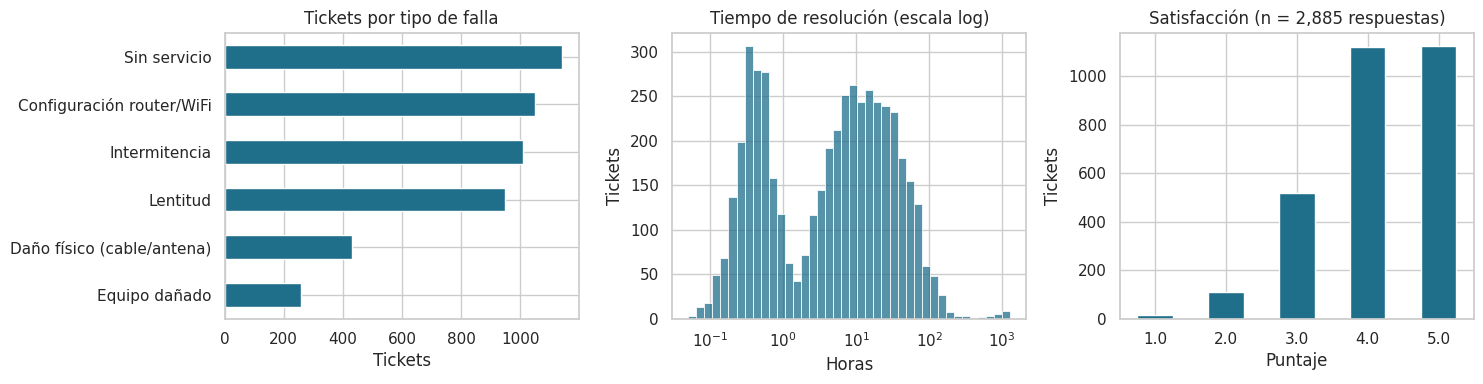

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["tipo_falla"].value_counts().sort_values().plot.barh(ax=ax[0], color="#1F6F8B")
ax[0].set(title="Tickets por tipo de falla", xlabel="Tickets", ylabel="")
sns.histplot(df["tiempo_resolucion_h"].dropna(), log_scale=True, bins=40, ax=ax[1], color="#1F6F8B")
ax[1].set(title="Tiempo de resolución (escala log)", xlabel="Horas", ylabel="Tickets")
df["satisfaccion"].value_counts().sort_index().plot.bar(ax=ax[2], color="#1F6F8B", rot=0)
ax[2].set(title=f"Satisfacción (n = {df['satisfaccion'].notna().sum():,} respuestas)", xlabel="Puntaje", ylabel="Tickets")
fig.tight_layout(); guardar(fig, "g0_univariado.png"); plt.show()

**Interpretación.** Las fallas más frecuentes son "Sin servicio" y "Configuración router/WiFi", cada una con más de mil tickets. El tiempo de resolución es **bimodal**: un grupo se resuelve en menos de una hora por teléfono y otro tarda de 10 a 100 horas porque requiere visita. Por eso la media no representa a ninguno de los dos y se trabaja con la mediana por nivel. La satisfacción es alta en general, con una cola de notas 1–2 que conviene explicar en el paso siguiente.

## Paso 5 · Análisis bivariado

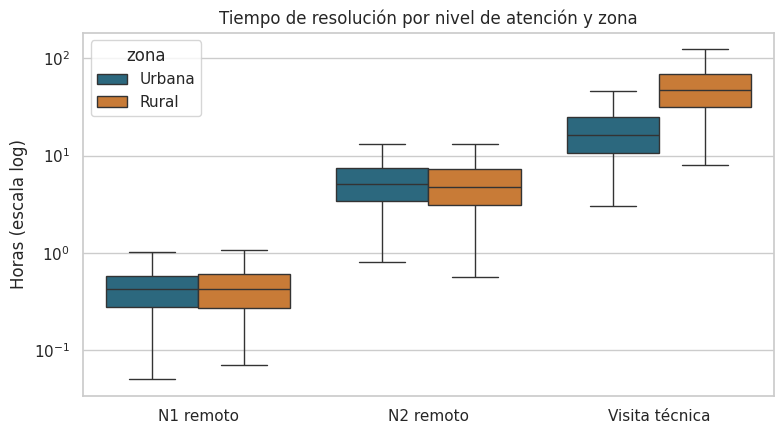

n  mediana_h  sla_pct
nivel_atencion zona                            
N1 remoto      Rural    481       0.42    99.79
               Urbana  1228       0.42    99.43
N2 remoto      Rural    365       4.78    99.45
               Urbana   715       5.08    99.86
Visita técnica Rural    776      46.88    66.32
               Urbana  1271      16.37    90.51

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="nivel_atencion", y="tiempo_resolucion_h", hue="zona",
            order=["N1 remoto", "N2 remoto", "Visita técnica"], showfliers=False, ax=ax,
            palette={"Urbana": "#1F6F8B", "Rural": "#E07A1F"})
ax.set(yscale="log", title="Tiempo de resolución por nivel de atención y zona",
       xlabel="", ylabel="Horas (escala log)")
fig.tight_layout(); guardar(fig, "g5_tiempo_nivel_zona.png"); plt.show()
resumen_por(df, ["nivel_atencion", "zona"])[["n", "mediana_h", "sla_pct"]]

**Interpretación.** En soporte remoto la zona casi no importa. En las **visitas técnicas**, la mediana rural es unas 3 veces la urbana y el cumplimiento de SLA cae a alrededor de dos tercios. El problema no está en la mesa de ayuda, sino en la **capacidad de campo rural**.

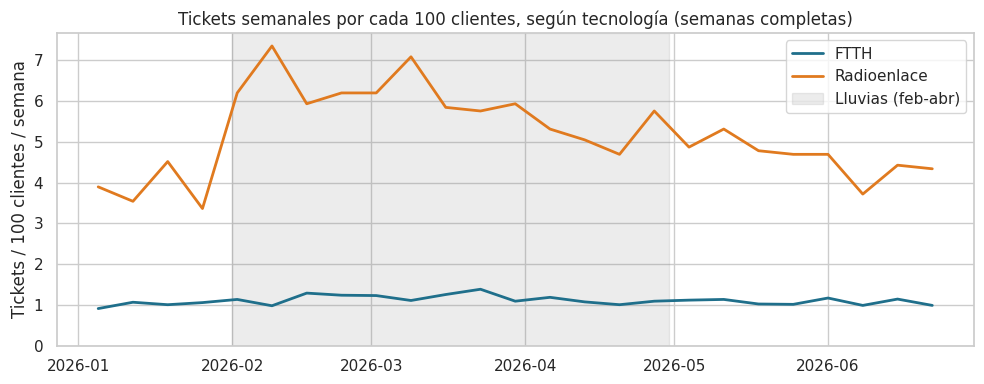

n  sla_pct  mediana_h
tecnologia  temporada                                  
FTTH        Lluvias (feb-abr)  1728    96.12       4.96
            Seca               1607    95.74       5.08
Radioenlace Lluvias (feb-abr)   861    80.84      12.27
            Seca                640    85.83       9.82

In [23]:
# Solo semanas completas (lunes a domingo dentro del periodo): las de los extremos
# tienen menos días y mostrarían una caída falsa.
completas = df["semana"].between(pd.Timestamp("2026-01-05"), pd.Timestamp("2026-06-22"))
semanal = (df[completas].groupby(["semana", "tecnologia"]).size().unstack()
             .div(nodos.groupby("tecnologia")["clientes_activos"].sum()) * 100)
fig, ax = plt.subplots(figsize=(10, 4))
for tec in semanal.columns:
    ax.plot(semanal.index, semanal[tec], label=tec, color=COLORES[tec], lw=2)
ax.axvspan(pd.Timestamp("2026-02-01"), pd.Timestamp("2026-04-30"), color="grey", alpha=.15, label="Lluvias (feb-abr)")
ax.set(title="Tickets semanales por cada 100 clientes, según tecnología (semanas completas)", ylabel="Tickets / 100 clientes / semana", ylim=(0, None))
ax.legend(); fig.tight_layout(); guardar(fig, "g4_serie_semanal.png"); plt.show()
resumen_por(df, ["tecnologia", "temporada"])[["n", "sla_pct", "mediana_h"]]

**Interpretación.** Por cada 100 clientes, el radioenlace genera varias veces más tickets que la fibra durante todo el semestre, y la diferencia se amplía en la temporada de lluvias, cuando además baja su cumplimiento de SLA. La fibra casi no reacciona a la lluvia.

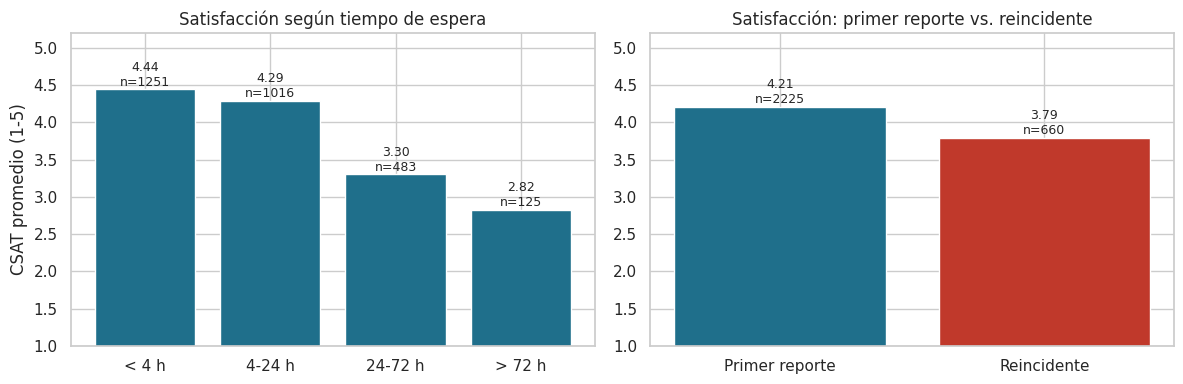

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
csat_t = df.assign(espera=pd.cut(df["tiempo_resolucion_h"], [0, 4, 24, 72, np.inf],
                                 labels=["< 4 h", "4-24 h", "24-72 h", "> 72 h"]))
t1 = resumen_por(csat_t, "espera")
ax[0].bar(t1.index.astype(str), t1["csat"], color="#1F6F8B")
for i, (v, n) in enumerate(zip(t1["csat"], t1["n_csat"])):
    ax[0].text(i, v + .05, f"{v:.2f}\nn={n}", ha="center", fontsize=9)
ax[0].set(ylim=(1, 5.2), title="Satisfacción según tiempo de espera", ylabel="CSAT promedio (1-5)", xlabel="")
t2 = resumen_por(df, "reincidencia_30d").rename(index={False: "Primer reporte", True: "Reincidente"})
ax[1].bar(t2.index, t2["csat"], color=["#1F6F8B", "#C0392B"])
for i, (v, n) in enumerate(zip(t2["csat"], t2["n_csat"])):
    ax[1].text(i, v + .05, f"{v:.2f}\nn={n}", ha="center", fontsize=9)
ax[1].set(ylim=(1, 5.2), title="Satisfacción: primer reporte vs. reincidente", ylabel="", xlabel="")
fig.tight_layout(); guardar(fig, "g6_satisfaccion.png"); plt.show()

**Interpretación.** La satisfacción cae de forma escalonada con la espera, y los clientes que reinciden califican peor. Reducir tiempos y reincidencias mejora directamente la experiencia del cliente, no solo un indicador interno.

## Paso 6 · Segmentación con n por grupo (T8)

**Decisión:** segmentar por **zona × tecnología** (3 segmentos) y luego por **nodo**, normalizando por clientes activos (tickets por 100 clientes al mes). **Justificación:** un nodo grande siempre tiene más tickets; la tasa permite comparar nodos de distinto tamaño. Todo grupo se muestra con su **n**, y los de **n < 30** se marcan con advertencia: con tan pocos tickets, un porcentaje puede cambiar mucho por azar y no debe usarse solo para decidir.

In [25]:
resumen_por(df, "segmento")

,n,sla_pct,fcr_pct,reincidencia_pct,visita_pct,mediana_h,csat,n_csat,advertencia
segmento,,,,,,,,,
Rural · FTTH,121,94.12,38.02,8.26,36.36,4.48,4.09,69,
Rural · Radioenlace,1501,82.95,28.98,33.04,48.77,11.17,3.82,897,
Urbana · FTTH,3214,96.01,38.21,18.54,39.55,5.05,4.26,1919,


El segmento **Rural · FTTH** (un solo nodo, Mejía) tiene n = 121 y rinde como la fibra urbana. Esto sugiere que la brecha rural se explica sobre todo por la **tecnología** (radioenlace) y por la distancia en las visitas, no por la zona en sí.

In [26]:
por_nodo = tasa_por_nodo(df, nodos)
por_nodo[["canton", "zona", "tecnologia", "clientes_activos", "n", "tickets_100_clientes_mes",
          "sin_servicio_pct", "sla_pct", "reincidencia_pct", "advertencia"]]

,canton,zona,tecnologia,clientes_activos,n,tickets_100_clientes_mes,sin_servicio_pct,sla_pct,reincidencia_pct,advertencia
nodo,,,,,,,,,,
N-OTA-02,Otavalo,Rural,Radioenlace,380,598,26.47,37.60,83.08,35.28,
N-CAY-02,Cayambe,Rural,Radioenlace,450,689,25.75,36.90,81.08,35.56,
N-PMQ-01,Pedro Moncayo,Rural,Radioenlace,300,214,12.00,28.00,88.68,18.69,
N-QTO-01,Quito,Urbana,FTTH,3200,952,5.00,16.50,96.42,17.75,
N-IBA-01,Ibarra,Urbana,FTTH,1600,468,4.92,18.80,95.94,12.39,
N-QTO-03,Quito,Urbana,FTTH,1900,551,4.88,19.20,96.55,19.60,
N-QTO-02,Quito,Urbana,FTTH,2800,807,4.85,19.70,95.28,18.34,
N-OTA-01,Otavalo,Urbana,FTTH,700,195,4.68,18.50,94.87,26.15,
N-CAY-01,Cayambe,Urbana,FTTH,900,241,4.50,14.90,96.65,25.73,


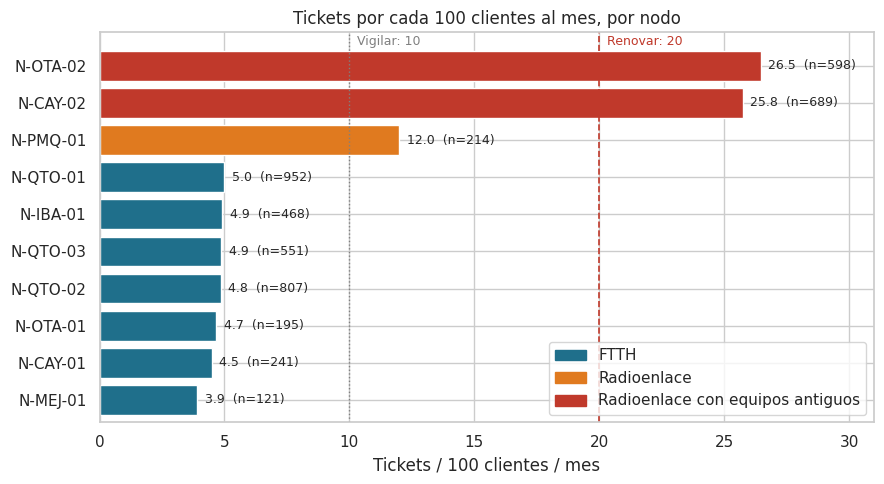

In [27]:
g = por_nodo.sort_values("tickets_100_clientes_mes")
colores = ["#C0392B" if c else COLORES[t] for c, t in zip(g["critico"], g["tecnologia"])]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(g.index, g["tickets_100_clientes_mes"], color=colores)
for i, (v, n) in enumerate(zip(g["tickets_100_clientes_mes"], g["n"])):
    ax.text(v + .3, i, f"{v:.1f}  (n={n})", va="center", fontsize=9)
ax.axvline(20, color="#C0392B", ls="--", lw=1.2)
ax.text(20.3, len(g) - 0.45, "Renovar: 20", fontsize=9, color="#C0392B")
ax.axvline(10, color="grey", ls=":", lw=1)
ax.text(10.3, len(g) - 0.45, "Vigilar: 10", fontsize=9, color="grey")
ax.set(title="Tickets por cada 100 clientes al mes, por nodo", xlabel="Tickets / 100 clientes / mes", xlim=(0, 31), ylim=(-0.6, len(g) - 0.1))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORES["FTTH"], label="FTTH"), Patch(color=COLORES["Radioenlace"], label="Radioenlace"),
                   Patch(color="#C0392B", label="Radioenlace con equipos antiguos")], loc="lower right")
fig.tight_layout(); guardar(fig, "g1_tasa_nodo.png"); plt.show()

**Interpretación.** Los nodos **N-OTA-02** y **N-CAY-02** generan ~26 tickets por 100 clientes al mes, más de 5 veces la fibra urbana (~5). Además, más de un tercio de sus tickets son "Sin servicio" y un tercio son reincidencias: la falla vuelve porque la causa (equipo antiguo) no se corrige con visitas.

In [28]:
visitas = df[df["visita"]]   # la cuadrilla viene de nodos.csv: Quito atiende Quito y Mejía; Norte, el resto
carga = visitas.groupby("cuadrilla").agg(visitas=("id_ticket", "size"), tecnicos=("tecnico_id", "nunique"),
                                         sla_pct=("cumple_sla", "mean"), mediana_h=("tiempo_resolucion_h", "median"))
carga["visitas_por_tecnico"] = carga["visitas"] / carga["tecnicos"]
carga["sla_pct"] *= 100
carga

,visitas,tecnicos,sla_pct,mediana_h,visitas_por_tecnico
cuadrilla,,,,,
Norte,1120,4,74.15,34.15,280.00
Quito,927,8,90.11,17.09,115.88


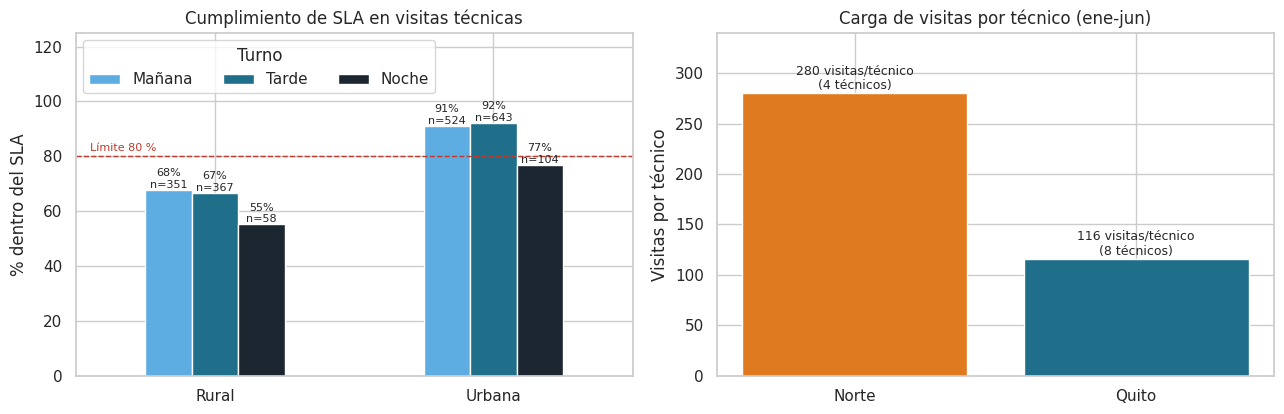

n  sla_pct  mediana_h advertencia
zona   turno                                      
Rural  Mañana  351    67.71      47.42            
       Noche    58    55.17      53.83            
       Tarde   367    66.76      44.75            
Urbana Mañana  524    91.17      16.20            
       Noche   104    76.92      24.01            
       Tarde   643    92.19      15.65

In [29]:
t_turno = resumen_por(visitas, ["zona", "turno"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
tt = t_turno["sla_pct"].unstack("turno")[["Mañana", "Tarde", "Noche"]]
tt.plot.bar(ax=ax[0], rot=0, color=["#5DADE2", "#1F6F8B", "#1B2631"])
ax[0].axhline(80, color="#C0392B", ls="--", lw=1)
ax[0].set(title="Cumplimiento de SLA en visitas técnicas", ylabel="% dentro del SLA", xlabel="", ylim=(0, 125))
ax[0].legend(title="Turno", ncol=3, loc="upper left")
ax[0].text(-0.45, 82, "Límite 80 %", color="#C0392B", fontsize=8, ha="left")
for cont, turno in zip(ax[0].containers, tt.columns):
    ns = t_turno.xs(turno, level="turno")["n"].reindex(tt.index)
    ax[0].bar_label(cont, labels=[f"{v:.0f}%\nn={n}" for v, n in zip(cont.datavalues, ns)], fontsize=8)
ax[1].bar(carga.index, carga["visitas_por_tecnico"], color=["#E07A1F", "#1F6F8B"])
for i, (v, t) in enumerate(zip(carga["visitas_por_tecnico"], carga["tecnicos"])):
    ax[1].text(i, v + 4, f"{v:.0f} visitas/técnico\n({t} técnicos)", ha="center", fontsize=9)
ax[1].set(title="Carga de visitas por técnico (ene-jun)", ylabel="Visitas por técnico", ylim=(0, 340))
fig.tight_layout(); guardar(fig, "g2_sla_visitas_carga.png"); plt.show()
t_turno[["n", "sla_pct", "mediana_h", "advertencia"]]

**Interpretación.** La cuadrilla Norte atiende **más visitas con la mitad de técnicos**: cada técnico carga unas 2,4 veces más trabajo que en Quito, y el SLA de sus visitas es 16 puntos menor (≈74 % vs. ≈90 %); en las visitas a zona rural baja a ≈66 %. Las visitas a Mejía, el nodo rural atendido desde Quito, cumplen el 86 % (n = 44), frente a ≈65 % en los radioenlaces rurales del Norte (n = 732): la distancia pesa, pero pesa más la falta de técnicos. El turno de noche es el peor en ambas zonas, aunque en zona rural su n es menor (58 visitas), así que ese dato se lee con cautela.

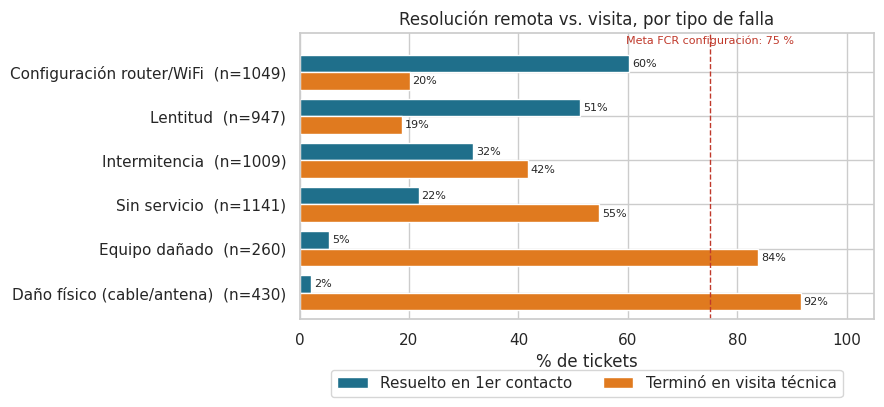

,n,fcr_pct,visita_pct,mediana_h
tipo_falla,,,,
Daño físico (cable/antena),430,2.09,91.63,18.60
Equipo dañado,260,5.38,83.85,16.31
Sin servicio,1141,21.74,54.78,10.80
Intermitencia,1009,31.71,41.72,6.62
Lentitud,947,51.32,18.80,1.17
Configuración router/WiFi,1049,60.25,20.11,0.68


In [30]:
t_tipo = resumen_por(df, "tipo_falla").sort_values("fcr_pct")
fig, ax = plt.subplots(figsize=(9, 4.3))
y = np.arange(len(t_tipo))
b1 = ax.barh(y + .2, t_tipo["fcr_pct"], .4, label="Resuelto en 1er contacto", color="#1F6F8B")
b2 = ax.barh(y - .2, t_tipo["visita_pct"], .4, label="Terminó en visita técnica", color="#E07A1F")
ax.bar_label(b1, fmt="%.0f%%", fontsize=8, padding=2); ax.bar_label(b2, fmt="%.0f%%", fontsize=8, padding=2)
ax.set_yticks(y, [f"{i}  (n={n})" for i, n in zip(t_tipo.index, t_tipo["n"])])
ax.axvline(75, color="#C0392B", ls="--", lw=1)
ax.text(75, len(t_tipo) - .35, "Meta FCR configuración: 75 %", fontsize=8, color="#C0392B", ha="center")
ax.set(title="Resolución remota vs. visita, por tipo de falla", xlabel="% de tickets", xlim=(0, 105),
       ylim=(-.6, len(t_tipo) - .1))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.15), ncol=2); fig.tight_layout(); guardar(fig, "g3_fcr_tipo.png"); plt.show()
t_tipo[["n", "fcr_pct", "visita_pct", "mediana_h"]]

**Interpretación.** "Configuración router/WiFi" es un problema que casi siempre se puede resolver a distancia. Aun así, solo ~60 % se resuelve en el primer contacto y **1 de cada 5 termina en visita técnica** (más de 200 salidas en el semestre), ocupando técnicos que hacen falta para daños físicos y caídas.

#### Regla de grupos pequeños en acción
Al bajar a un nivel más fino, varios grupos quedan con n < 30. Por ejemplo, en el nodo de Mejía por tipo de falla:

In [31]:
resumen_por(df[df["nodo"] == "N-MEJ-01"], "tipo_falla")[["n", "sla_pct", "advertencia"]]

,n,sla_pct,advertencia
tipo_falla,,,
Configuración router/WiFi,36,100.00,
Daño físico (cable/antena),10,80.00,n < 30
Equipo dañado,7,100.00,n < 30
Intermitencia,15,92.86,n < 30
Lentitud,33,96.97,
Sin servicio,20,84.21,n < 30


Un 80 % de SLA con n = 10 equivale a 2 tickets incumplidos: no es evidencia suficiente para actuar sobre ese nodo. El dashboard aplica la misma regla y muestra una advertencia cuando un filtro deja grupos pequeños.

In [32]:
# Evidencia numérica usada en las decisiones (se calcula, no se escribe a mano)
criticos = por_nodo[por_nodo["critico"]]
fibra_urb = por_nodo.query("zona == 'Urbana' and tecnologia == 'FTTH'")
cfg = t_tipo.loc["Configuración router/WiFi"]
ev = {
    "tasa_criticos": criticos["tickets_100_clientes_mes"].mean(),
    "tasa_fibra_urbana": fibra_urb["tickets_100_clientes_mes"].mean(),
    "reinc_criticos": criticos["reincidencia_pct"].mean(),
    "sla_visitas_norte": carga.loc["Norte", "sla_pct"], "sla_visitas_quito": carga.loc["Quito", "sla_pct"],
    "carga_norte": carga.loc["Norte", "visitas_por_tecnico"], "carga_quito": carga.loc["Quito", "visitas_por_tecnico"],
    "fcr_config": cfg["fcr_pct"], "visitas_config": int(round(cfg["n"] * cfg["visita_pct"] / 100)),
}
pd.Series(ev).round(1).to_frame("valor")

,valor
tasa_criticos,26.10
tasa_fibra_urbana,4.80
reinc_criticos,35.40
sla_visitas_norte,74.10
sla_visitas_quito,90.10
carga_norte,280.00
carga_quito,115.90
fcr_config,60.20
visitas_config,211.00


## Paso 7 · Conclusiones y decisiones (C6)

**Respuesta a la pregunta.** Los incumplimientos de SLA y las reincidencias no se reparten de forma pareja: se concentran en (a) **dos nodos de radioenlace con equipos antiguos**, (b) las **visitas técnicas rurales**, atendidas por una cuadrilla sobrecargada, y (c) **visitas evitables** por problemas de configuración que podrían resolverse a distancia.

| # | Decisión | Evidencia (datos) | Responsable | Indicador de seguimiento | Límite / regla de activación |
|---|---|---|---|---|---|
| D1 | **Renovar los equipos de radioenlace** de los nodos críticos N-CAY-02 y N-OTA-02 | ~26 tickets/100 clientes/mes vs. ~5 en fibra urbana; >35 % "Sin servicio"; ~35 % de reincidencia frente a 22,8 % global | Jefe de Red / NOC | Tickets por 100 clientes al mes, por nodo | **> 20**: renovación. Entre 10 y 20: vigilancia (hoy, N-PMQ-01 con 12,0). Meta: < 12 en los nodos renovados al cierre del 3.er trimestre |
| D2 | **Reasignar 2 técnicos** de la cuadrilla Quito a la cuadrilla Norte (base en Cayambe) | Carga Norte ~280 visitas/técnico vs. ~116 en Quito; SLA de visitas Norte ~74 % vs. Quito ~90 % (visitas rurales ~66 %) | Coordinadora de Operaciones de Soporte | % de visitas rurales dentro del SLA, semanal | Si baja de **80 %** durante 2 semanas seguidas, se activa un refuerzo temporal. Vigilar que Quito no baje de 85 % tras la reasignación |
| D3 | **Capacitar a la mesa de ayuda (N1)** con un guion de diagnóstico remoto de router/WiFi y habilitar la gestión remota del router antes de programar una visita | FCR en configuración ~60 %; ~210 visitas por configuración en el semestre | Supervisor de Mesa de Ayuda | FCR mensual en "Configuración router/WiFi" | Meta **≥ 75 %**. Si queda por debajo 2 meses seguidos, se repite la capacitación y se audita una muestra de 30 tickets escalados |

**Coherencia.** D1 ataca la causa de las fallas (equipos), D2 la capacidad de respuesta cuando la falla ocurre y D3 libera horas de técnicos para D2. Las tres se miden con indicadores que ya existen en el dashboard.

### Limitaciones
- Los datos son **simulados**: las magnitudes dependen de los supuestos del generador. El valor del proyecto está en el método, que puede aplicarse a una exportación real del CRM sin cambiar el código de limpieza.
- La asociación entre tecnología y fallas se confunde parcialmente con la zona: solo hay un nodo de fibra rural (n = 121).
- El CSAT tiene ≈40 % de no respuesta y puede estar sesgado si los más insatisfechos responden más o menos.
- La reincidencia a 30 días no distingue si el segundo reporte es por la misma causa.